# Импорт библиотек

In [1]:
# based on https://www.kaggle.com/konstanter/fasterrcnn-pytorch-maskdetection

import numpy as np 
import pandas as pd 
import torchvision
from torchvision import transforms, datasets, models
import torch
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import xml.etree.ElementTree as et
import albumentations as A
from albumentations.pytorch.transforms import ToTensorV2
import cv2
import os
import glob

In [2]:
torch.cuda.is_available()

True

# Загрузка данных в DataLoader

In [ ]:
# путь к файлам
images_dir = './images/'
annotations_dir = './annotations/'


class FaceMaskDataset(torch.utils.data.Dataset):

    def __init__(self, images_dir, annotation_dir,width, height, transforms=None):
        self.transforms = transforms
        self.images_dir = images_dir
        self.annotation_dir = annotation_dir
        self.height = height
        self.width = width
        
        # сортировка изображений
        self.imgs = [image for image in sorted(os.listdir(images_dir))]
        self.annotate = [image for image in sorted(os.listdir(annotation_dir))]
        
        # на 0й позиции находится фон
        self.classes = ['_', 'without_mask','with_mask','mask_weared_incorrect']

    def __getitem__(self, idx):

        img_name = self.imgs[idx]
        image_path = os.path.join(self.images_dir, img_name)

        # изменение цвета и размера изображения    
        img = cv2.imread(image_path)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32)
        img_res = cv2.resize(img_rgb, (self.width, self.height), cv2.INTER_AREA)
        # нормализация изображения
        img_res /= 255.0
        
        # аннотация
        annot_filename = self.annotate[idx]
        annot_file_path = os.path.join(self.annotation_dir, annot_filename)
        
        boxes = []
        labels = []
        tree = et.parse(annot_file_path)
        root = tree.getroot()
        
        # высота и ширина изобрадения
        wt = img.shape[1]
        ht = img.shape[0]
        
        # ограничивающие рамки
        for member in root.findall('object'):
            labels.append(self.classes.index(member.find('name').text))
            
            # bounding box
            xmin = int(member.find('bndbox').find('xmin').text)
            xmax = int(member.find('bndbox').find('xmax').text)
            
            ymin = int(member.find('bndbox').find('ymin').text)
            ymax = int(member.find('bndbox').find('ymax').text)
            
            
            xmin_corr = (xmin/wt)*self.width
            xmax_corr = (xmax/wt)*self.width
            ymin_corr = (ymin/ht)*self.height
            ymax_corr = (ymax/ht)*self.height
            
            # обрезаем по границам: аннотации бывают чуть "за кадром"
            xmin_corr = max(0.0, min(xmin_corr, self.width - 1.0))
            ymin_corr = max(0.0, min(ymin_corr, self.height - 1.0))
            xmax_corr = max(1.0, min(xmax_corr, float(self.width)))
            ymax_corr = max(1.0, min(ymax_corr, float(self.height)))
            
            
            boxes.append([xmin_corr, ymin_corr, xmax_corr, ymax_corr])
        
        # перевод boxes в формат torch.Tensor
        boxes = torch.as_tensor(boxes, dtype=torch.float32)
        
        area = (boxes[:, 3] - boxes[:, 1]) * (boxes[:, 2] - boxes[:, 0])

        iscrowd = torch.zeros((boxes.shape[0],), dtype=torch.int64)
        
        labels = torch.as_tensor(labels, dtype=torch.int64)


        target = {}
        target["boxes"] = boxes
        target["labels"] = labels
        target["area"] = area
        target["iscrowd"] = iscrowd

        image_id = torch.tensor([idx])
        target["image_id"] = image_id


        if self.transforms:
            
            sample = self.transforms(image = img_res,
                                     bboxes = boxes.numpy(),
                                     labels = labels.numpy())
            
            img_res = sample['image']
            target['boxes'] = torch.as_tensor(sample['bboxes'], dtype=torch.float32)
            target['labels'] = torch.as_tensor(sample['labels'], dtype=torch.int64)
            
            
        return img_res, target

    def __len__(self):
        return len(self.imgs)


# проверка датасета
dataset = FaceMaskDataset(images_dir, annotations_dir, 224, 224)
print('length of dataset = ', len(dataset), '\n')

img, target = dataset[78]
print('Image shape = ', img.shape, '\n','Target - ', target)

length of dataset =  853 

Image shape =  (224, 224, 3) 
 Target -  {'boxes': tensor([[113.1163, 146.7200, 163.7209, 205.5200]]), 'labels': tensor([2]), 'area': tensor([2975.5537]), 'iscrowd': tensor([0]), 'image_id': tensor([78])}


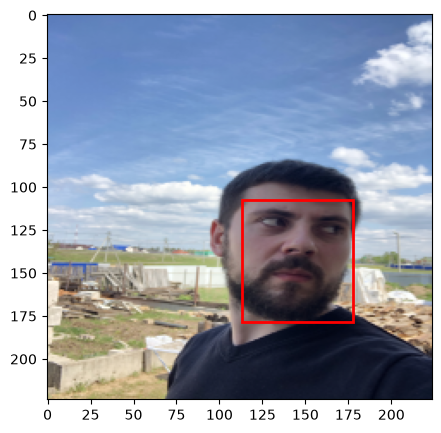

In [4]:
# Вспомогательная функция для визуализации bbox

def plot_img_bbox(img, target):
    fig, a = plt.subplots(1,1)
    fig.set_size_inches(5,5)
    a.imshow(img)
    for box in (target['boxes']):
        x, y, width, height  = box[0], box[1], box[2]-box[0], box[3]-box[1]
        rect = patches.Rectangle((x, y),
                                 width, height,
                                 linewidth = 2,
                                 edgecolor = 'r',
                                 facecolor = 'none')

        # Отрисуем bbox поверх картинки
        a.add_patch(rect)
    plt.show()
rm = np.random.randint(0,100)    
img, target = dataset[rm]
plot_img_bbox(img, target)

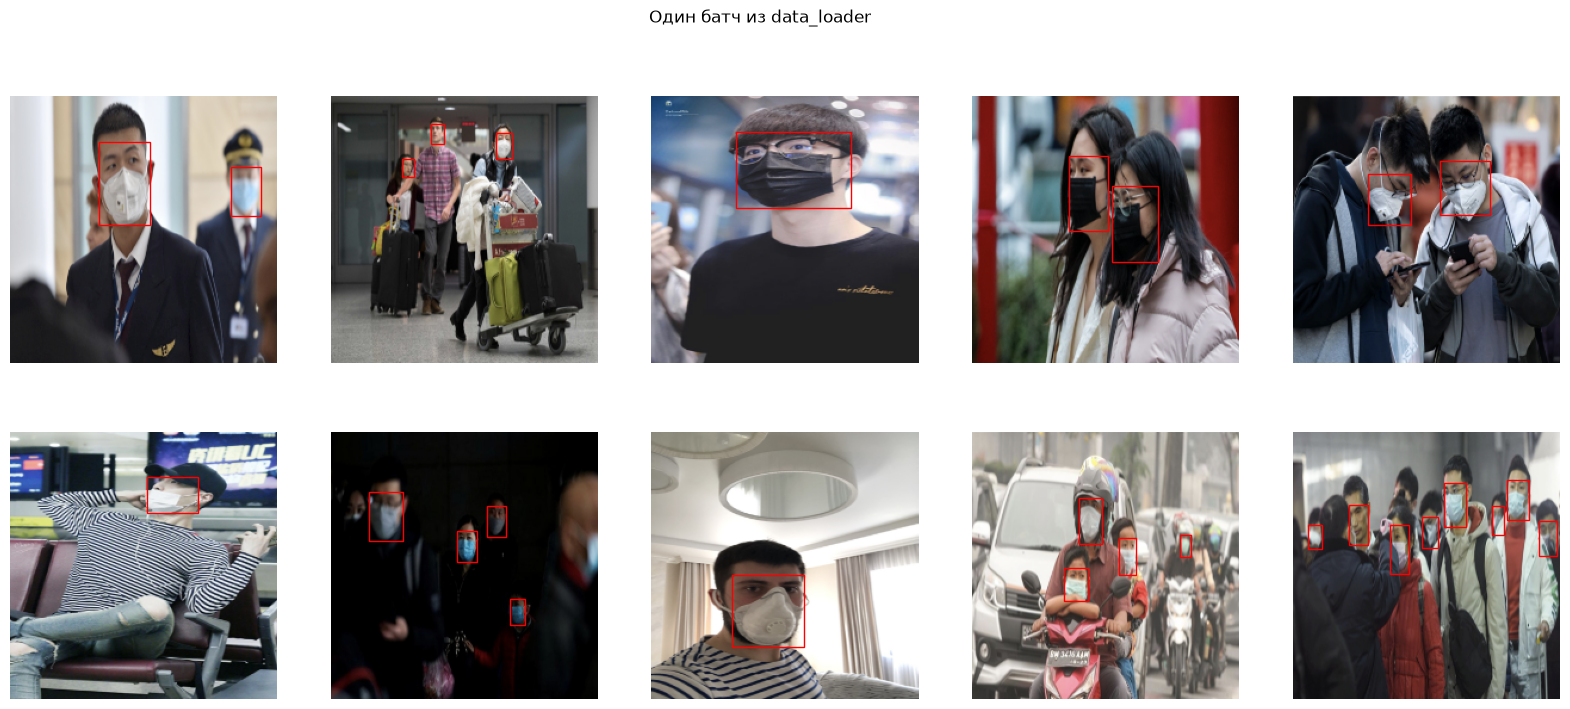

In [47]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, img, ann in zip(axes.flat, imgs, annotations):
    ax.imshow(img.detach().cpu().permute(1, 2, 0))
    for box in ann['boxes'].detach().cpu().numpy():
        x, y = box[0], box[1]
        ax.add_patch(patches.Rectangle((x, y), box[2]-box[0], box[3]-box[1],
                                       linewidth=1, edgecolor='r', facecolor='none'))
    ax.axis('off')
plt.suptitle('Один батч из data_loader')
plt.show()

In [5]:
def collate_fn(batch):
    return tuple(zip(*batch))

In [ ]:


# dataset_test создаётся с применением трансформации для тестового набора
def get_transform(train):
    if train:
        return A.Compose(
            [
                A.HorizontalFlip(0.5),
                A.RandomBrightnessContrast(p=0.2),
                A.ShiftScaleRotate(shift_limit=0.2, scale_limit=0.2, rotate_limit=30, p=0.5),
                ToTensorV2(p=1.0),
            ],
            bbox_params=A.BboxParams(
                format="pascal_voc",
                label_fields=["labels"],
                clip=True,
                min_area=1,
            ),
        )
    else:
        return A.Compose(
            [
                ToTensorV2(p=1.0),
            ],
            bbox_params=A.BboxParams(
                format="pascal_voc",
                label_fields=["labels"],
                clip=True,
                min_area=1,
            ),
        )
        
dataset_full = FaceMaskDataset(
    images_dir, annotations_dir, 224, 224, transforms=get_transform(train=True))

dataset_test = FaceMaskDataset(
    images_dir, annotations_dir, 224, 224, transforms=get_transform(train=False)
)

# разделим данные на train и test
torch.manual_seed(1)
indices = torch.randperm(len(dataset_full)).tolist()

test_split = 0.2
tsize = int(len(dataset_full)*test_split)
dataset = torch.utils.data.Subset(dataset_full, indices[:-tsize])
dataset_test = torch.utils.data.Subset(dataset_test, indices[-tsize:])

data_loader = torch.utils.data.DataLoader(
    dataset, batch_size=10, shuffle=True, num_workers=0,
    collate_fn=collate_fn)

data_loader_test = torch.utils.data.DataLoader(
    dataset_test, batch_size=10, shuffle=False, num_workers=0,
    collate_fn=collate_fn)



c:\Users\user\miniconda3\envs\cv\Lib\site-packages\albumentations\core\composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


In [7]:
dataset
sample = dataset[0]
print(type(sample), len(sample))
img, target = sample
print(type(img), getattr(img, "shape", None))
print(target.keys())
print(target["boxes"].shape, target["boxes"].dtype)
print(target["labels"].shape, target["labels"].dtype)

<class 'tuple'> 2
<class 'torch.Tensor'> torch.Size([3, 224, 224])
dict_keys(['boxes', 'labels', 'area', 'iscrowd', 'image_id'])
torch.Size([2, 4]) torch.float32
torch.Size([2]) torch.int64


In [8]:
dataset[10]

(tensor([[[5.3704e-01, 6.3202e-01, 7.2595e-01,  ..., 1.6041e-01,
           1.2000e-01, 2.7724e-01],
          [5.0314e-01, 6.0818e-01, 6.7926e-01,  ..., 1.8313e-01,
           1.0726e-01, 3.0812e-01],
          [5.1155e-01, 5.9615e-01, 6.9798e-01,  ..., 1.9461e-01,
           1.2451e-01, 3.7074e-01],
          ...,
          [4.7358e-01, 4.8646e-01, 5.9000e-01,  ..., 8.1928e-01,
           6.9168e-01, 1.4580e-01],
          [4.7951e-01, 5.0338e-01, 5.5736e-01,  ..., 2.7415e-01,
           2.6591e-01, 9.7539e-04],
          [5.1379e-01, 5.3997e-01, 5.4163e-01,  ..., 6.0368e-04,
           5.8711e-04, 0.0000e+00]],
 
         [[4.2641e-01, 5.3649e-01, 6.1642e-01,  ..., 1.7609e-01,
           1.3569e-01, 2.9293e-01],
          [4.0124e-01, 5.0873e-01, 5.6949e-01,  ..., 1.9506e-01,
           1.2614e-01, 3.2379e-01],
          [4.1909e-01, 4.9534e-01, 5.7287e-01,  ..., 2.1030e-01,
           1.4020e-01, 3.8404e-01],
          ...,
          [4.2727e-01, 4.2087e-01, 5.0774e-01,  ..., 8.192

Выбор модели. Faster R-CNN с backbone ResNet-50 + FPN: двухстадийный детектор, эталон качества в detection-задачах; предобучен на COCO (91 класс, включая «person»), что важно — лица на наших фото близки к COCO-данным, transfer learning сработает хорошо. FPN позволяет детектировать маски разного масштаба (лица вдали/вблизи). Заменяем только «голову» (FastRCNNPredictor) под 4 класса — остальная сеть дообучается. Вторая модель — YOLOv8s: одностадийный детектор, компромисс скорость/качество, для сравнения парадигм (two-stage vs one-stage).

# Обучение модели

In [9]:
def get_model_instance_segmentation(num_classes):
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)
   
    in_features = model.roi_heads.box_predictor.cls_score.in_features

    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    return model

In [10]:
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

num_classes = 4

print('device = ', device, '\n')

model = get_model_instance_segmentation(num_classes)

num_epochs = 4

model.to(device)


params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.005,
                                momentum=0.9, weight_decay=0.0005)

lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer,
                                               step_size=3,
                                               gamma=0.1)
len_dataloader = len(data_loader)

for epoch in range(num_epochs):
    model.train()
    i = 0    
    epoch_loss = 0
    for imgs, annotations in data_loader:
        i += 1
        imgs = [img.float().to(device) for img in imgs]
        annotations = [{k: v.to(device) for k, v in t.items()} for t in annotations]
        loss_dict = model(imgs, annotations)
        losses = sum(loss for loss in loss_dict.values())        

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()         
        epoch_loss += losses.item()
    lr_scheduler.step()  # <-- без этого шага scheduler бесполезен
    print(f'Epoch {epoch}: mean_loss = {epoch_loss / len(data_loader):.4f}')


c:\Users\user\miniconda3\envs\cv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\user\miniconda3\envs\cv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


device =  cuda 

Epoch 0: mean_loss = 0.5211
Epoch 1: mean_loss = 0.3338
Epoch 2: mean_loss = 0.2710
Epoch 3: mean_loss = 0.2300


In [11]:
# вспомогательная функция принимает исходный прогноз и порог iou

def apply_nms(orig_prediction, iou_thresh=0.3):
    
    keep = torchvision.ops.nms(orig_prediction['boxes'], orig_prediction['scores'], iou_thresh)
    
    final_prediction = orig_prediction
    final_prediction['boxes'] = final_prediction['boxes'][keep]
    final_prediction['scores'] = final_prediction['scores'][keep]
    final_prediction['labels'] = final_prediction['labels'][keep]
    
    return final_prediction

def torch_to_pil(img):
    return transforms.ToPILImage()(img).convert('RGB')

In [15]:
img, target = dataset_test[4]

model.eval()
with torch.no_grad():
    prediction = model([img.to(device)])[0]

# переносим предсказание на CPU: дальше с ним работает matplotlib и NMS
prediction = {k: v.cpu() for k, v in prediction.items()}
    
print('predicted #boxes: ', len(prediction['labels']))
print('real #boxes: ', len(target['labels']))

predicted #boxes:  2
real #boxes:  1


In [ ]:
from torchmetrics.detection import MeanAveragePrecision

metric = MeanAveragePrecision(iou_type="bbox", class_metrics=True)
model.eval()
with torch.no_grad():
    for imgs_v, anns_v in data_loader_test:
        imgs_v = [img.to(device) for img in imgs_v]
        preds_v = model(imgs_v)
        # torchmetrics ждёт оба на одном устройстве; переводим target на GPU
        anns_v = [{k: v.to(device) for k, v in t.items()} for t in anns_v]
        metric.update(preds_v, anns_v)

res = metric.compute()
print(f"mAP@0.5:0.95 = {res['map']:.4f}")
print(f"mAP@0.5      = {res['map_50']:.4f}")
print(f"AP per class = {res['map_per_class']}")  # классы: without_mask, with_mask, mask_weared_incorrect

EXPECTED OUTPUT


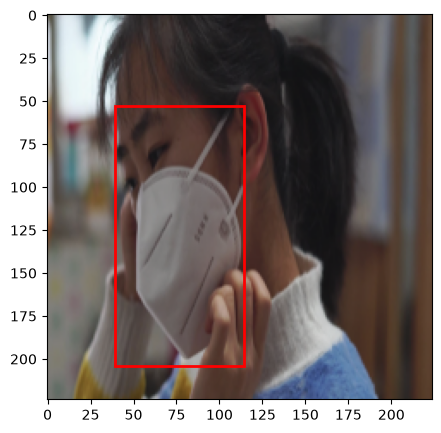

In [16]:
print('EXPECTED OUTPUT')
plot_img_bbox(torch_to_pil(img), target)

MODEL OUTPUT


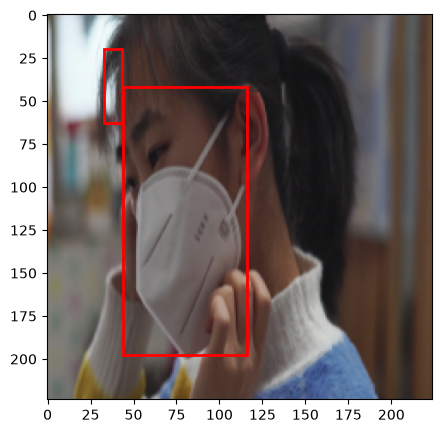

In [17]:
print('MODEL OUTPUT')
plot_img_bbox(torch_to_pil(img), prediction)

NMS APPLIED MODEL OUTPUT


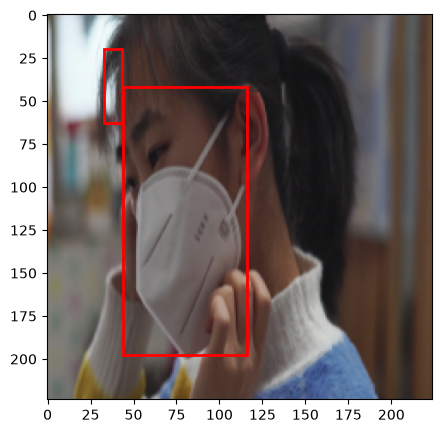

In [18]:
nms_prediction = apply_nms(prediction, iou_thresh=0.2)
print('NMS APPLIED MODEL OUTPUT')
plot_img_bbox(torch_to_pil(img), nms_prediction)

# Отрисовка изображений

In [36]:
def plot_image(img_tensor, annotation, predict=True):
    
    fig,ax = plt.subplots(1)
    fig.set_size_inches(18.5, 10.5)
    img = img_tensor.detach().cpu()
    mask_dic = {1:'without_mask', 2:'with_mask', 3:'mask_weared_incorrect'}

    ax.imshow(img.permute(1, 2, 0))
    
     # единообразно забираем всё на CPU и в numpy/числа
    boxes = annotation['boxes'].detach().cpu().numpy()
    labels = annotation['labels'].detach().cpu().numpy()
    scores = annotation['scores'].detach().cpu().numpy() if predict else None
    
    for i,box in enumerate(boxes):
        xmin, ymin, xmax, ymax = box

        rect = patches.Rectangle((xmin,ymin),(xmax-xmin),(ymax-ymin),linewidth=1,edgecolor='r',facecolor='none')

        ax.add_patch(rect)
        label = mask_dic[int(labels[i])]
        if predict:
            score=int(scores[i] * 100)
            ax.text(xmin, ymin, f"{label} : {score}%", horizontalalignment='center', verticalalignment='center',fontsize=20,color='b')
        else:
            
            ax.text(xmin, ymin, f"{label}", horizontalalignment='center', verticalalignment='center',fontsize=20,color='b')
    plt.show()

In [37]:
for imgs, annotations in data_loader:
        imgs = list(img.to(device) for img in imgs)
        annotations = [{k: v.to(device) for k, v in t.items()} for t in annotations]
        break

In [38]:
model.eval()
preds = model(imgs)

Prediction


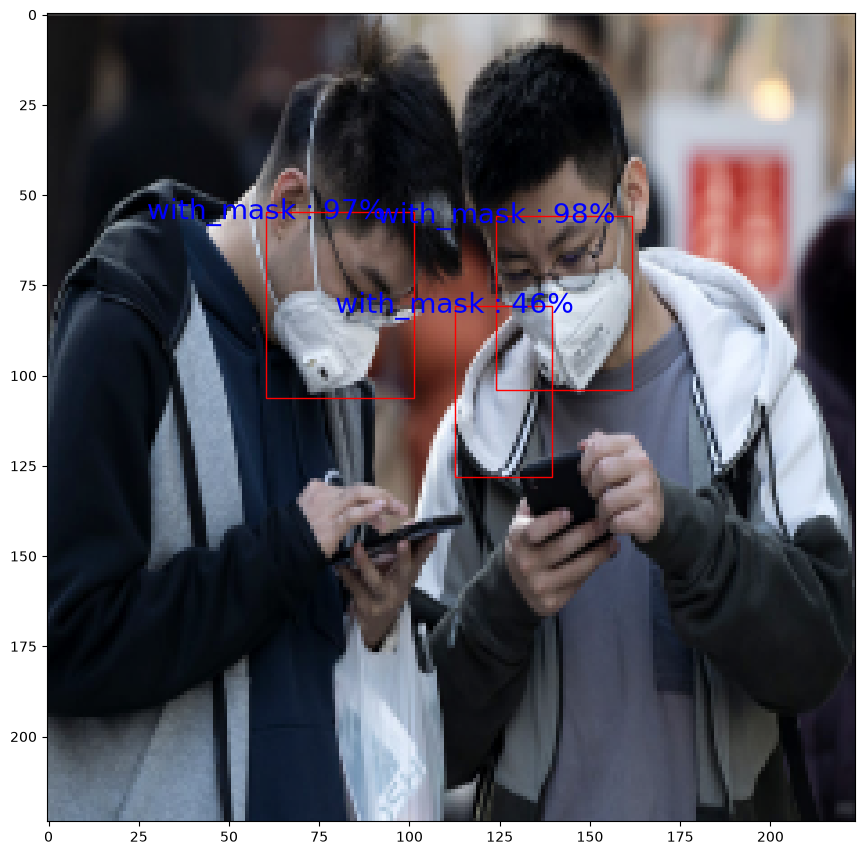

Target


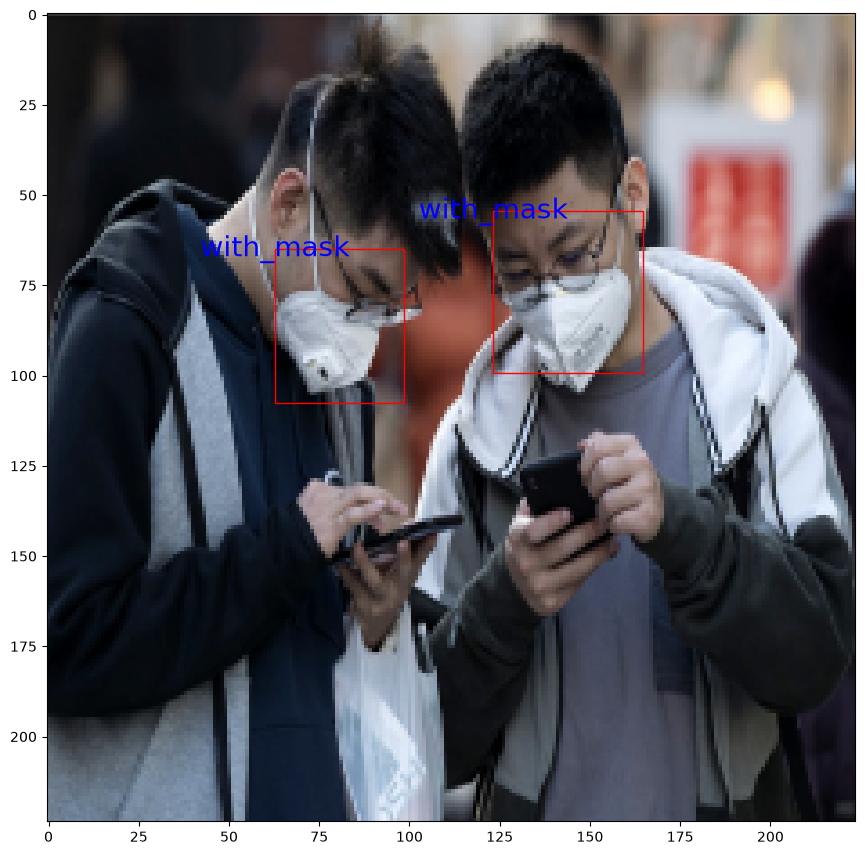

In [39]:
nms_prediction = apply_nms(preds[4], iou_thresh=0.2)
print("Prediction")
plot_image(imgs[4], nms_prediction)
print("Target")
plot_image(imgs[4].to('cpu'), annotations[4],False)

Prediction


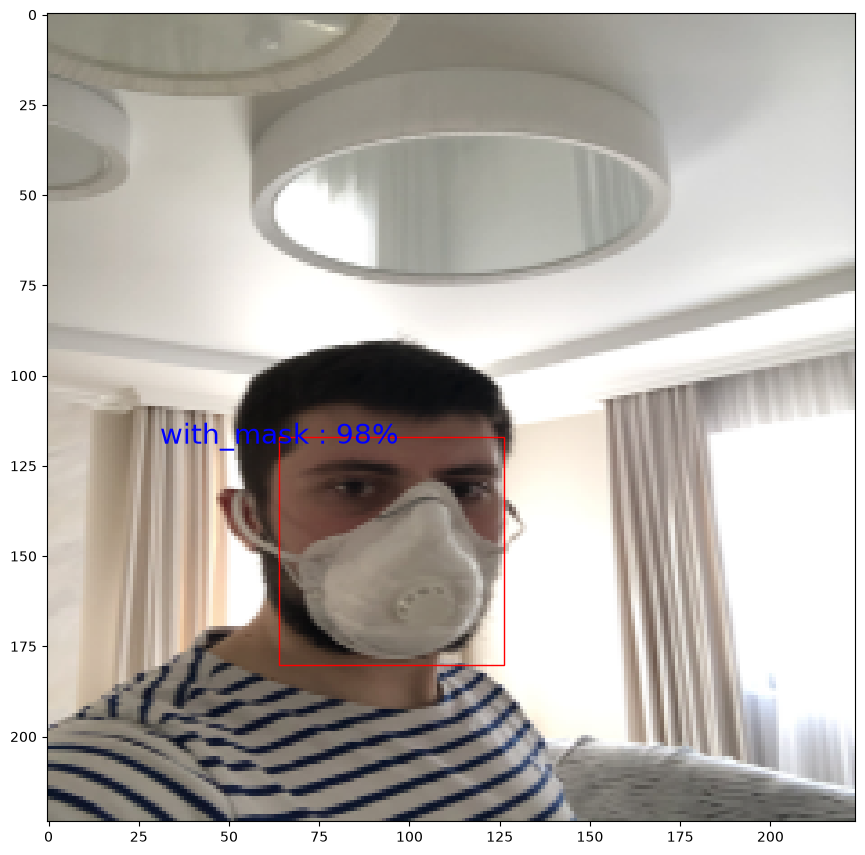

Target


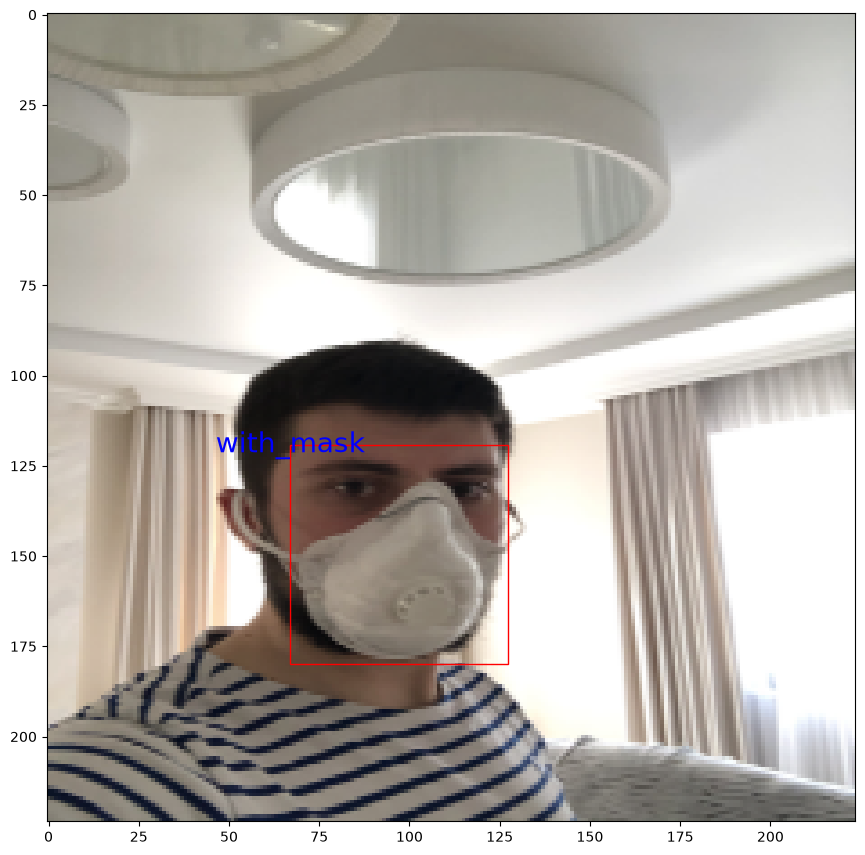

In [40]:
nms_prediction = apply_nms(preds[7], iou_thresh=0.2)
print("Prediction")
plot_image(imgs[7], nms_prediction)
print("Target")
plot_image(imgs[7].to('cpu'), annotations[7],False)

Prediction


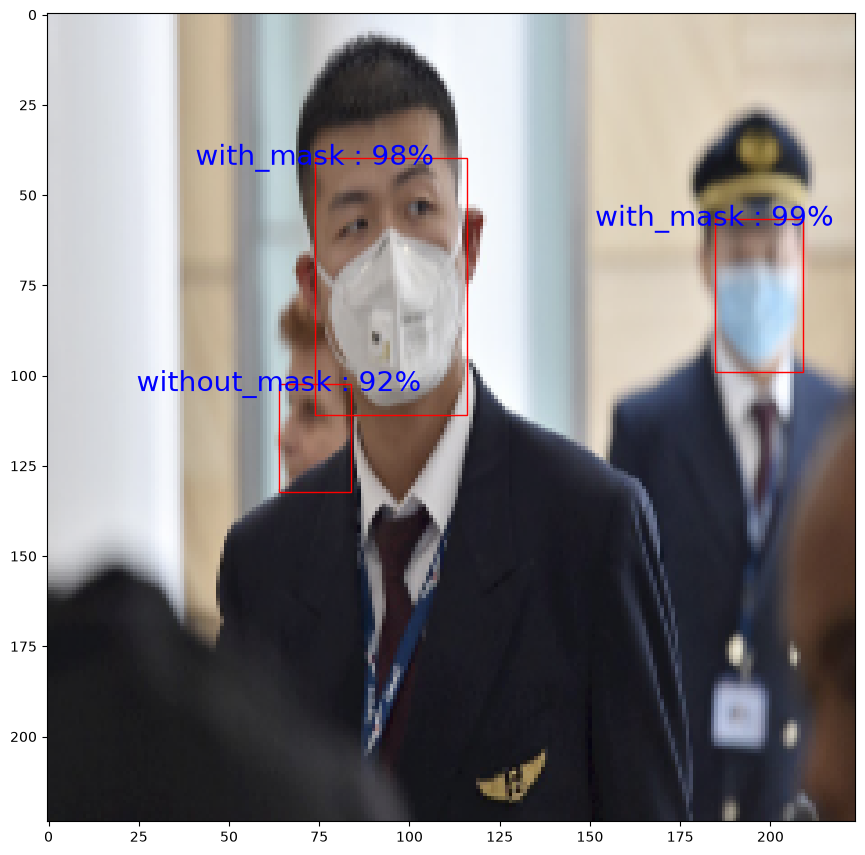

Target


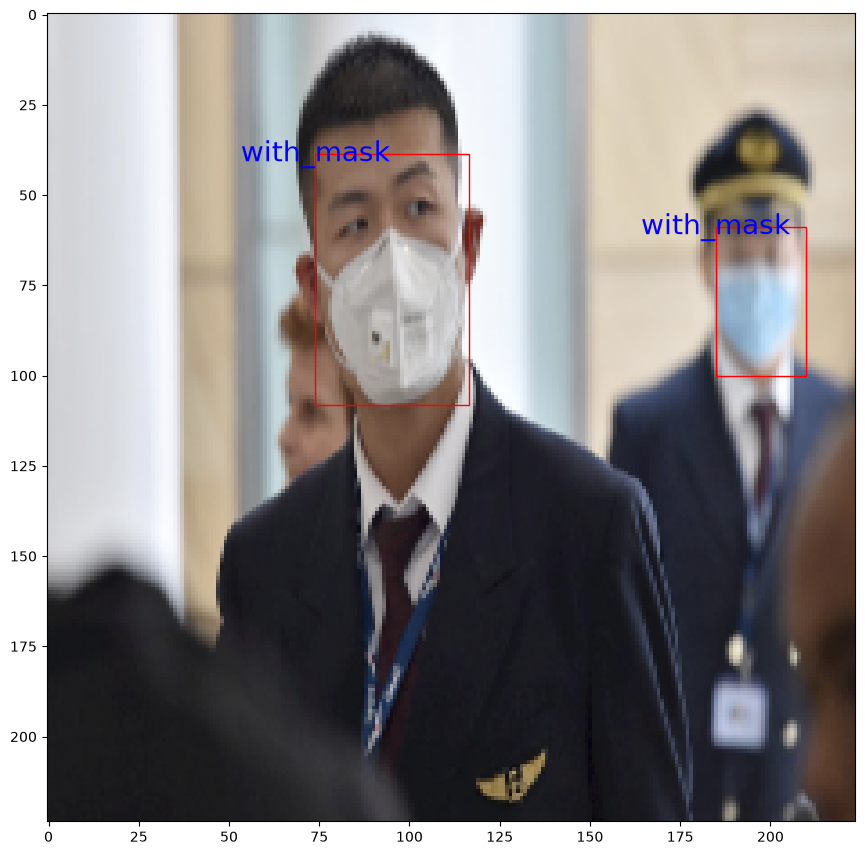

In [41]:
nms_prediction = apply_nms(preds[0], iou_thresh=0.2)
print("Prediction")
plot_image(imgs[0], nms_prediction)
print("Target")
plot_image(imgs[0].to('cpu'), annotations[0],False)

Prediction


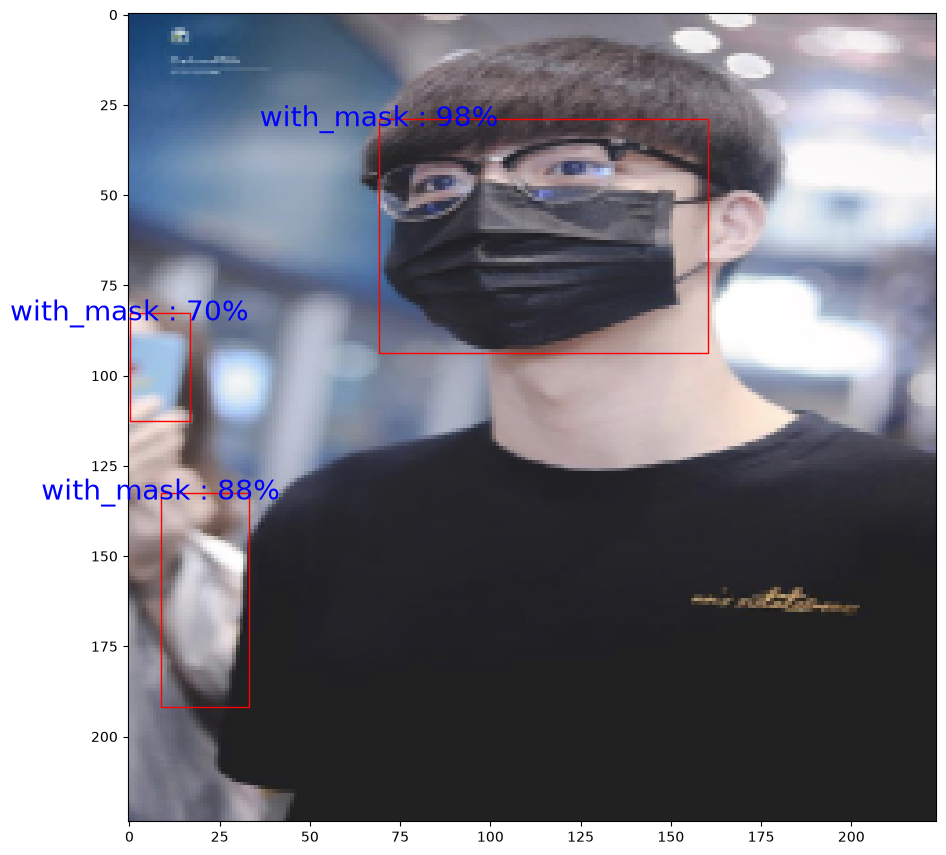

Target


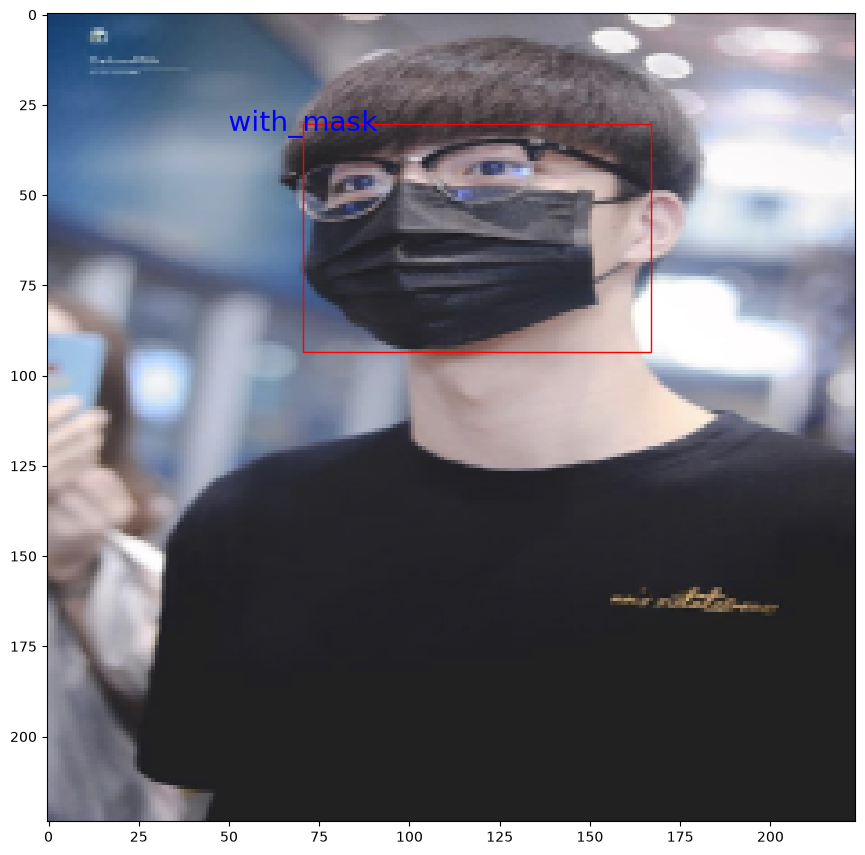

In [42]:
nms_prediction = apply_nms(preds[2], iou_thresh=0.2)
print("Prediction")
plot_image(imgs[2], nms_prediction)
print("Target")
plot_image(imgs[2].to('cpu'), annotations[2],False)

In [ ]:
from torchvision.ops import box_iou

names = {1: 'without_mask', 2: 'with_mask', 3: 'mask_weared_incorrect'}
curves = {c: {'scores': [], 'hits': [], 'n_gt': 0} for c in names}

model.eval()
with torch.no_grad():
    for imgs_v, anns_v in data_loader_test:
        preds_v = model([img.to(device) for img in imgs_v])
        for p, t in zip(preds_v, anns_v):
            p = {k: v.cpu() for k, v in p.items()}
            iou = box_iou(p['boxes'], t['boxes']) if len(p['boxes']) and len(t['boxes']) else None
            for c in names:
                gt_mask = t['labels'] == c
                curves[c]['n_gt'] += int(gt_mask.sum())
                pm = p['labels'] == c
                for s, bi in zip(p['scores'][pm], p['boxes'][pm]):
                    hit = False
                    if iou is not None and gt_mask.any():
                        j = (p['boxes'] == bi).all(dim=1).nonzero()[0, 0]
                        hit = bool((iou[j][gt_mask] >= 0.5).any())
                    curves[c]['scores'].append(float(s))
                    curves[c]['hits'].append(hit)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (c, d) in zip(axes, curves.items()):
    order = np.argsort(d['scores'])[::-1]
    hits = np.array(d['hits'])[order]
    tp = np.cumsum(hits)
    prec = tp / (np.arange(len(hits)) + 1)
    rec = tp / max(d['n_gt'], 1)
    ax.plot(rec, prec); ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
    ax.set_title(f'{names[c]} (IoU≥0.5)'); ax.grid(True)
plt.show()

## Модель YOLOv8

In [43]:
import os, shutil
import xml.etree.ElementTree as et

src_img, src_ann = './images/', './annotations/'
classes = ['without_mask', 'with_mask', 'mask_weared_incorrect']  # id: 0,1,2

def convert(split, img_names, out_root='./yolo_data'):
    for sub in ['images', 'labels']:
        os.makedirs(f'{out_root}/{sub}/{split}', exist_ok=True)
    for name in img_names:
        base = os.path.splitext(name)[0]
        shutil.copy(os.path.join(src_img, name), f'{out_root}/images/{split}/{name}')
        root = et.parse(os.path.join(src_ann, base + '.xml')).getroot()
        w = float(root.find('size/width').text)
        h = float(root.find('size/height').text)
        lines = []
        for obj in root.findall('object'):
            cid = classes.index(obj.find('name').text)
            bb = obj.find('bndbox')
            xmin, ymin = float(bb.find('xmin').text), float(bb.find('ymin').text)
            xmax, ymax = float(bb.find('xmax').text), float(bb.find('ymax').text)
            xc, yc = (xmin + xmax) / 2 / w, (ymin + ymax) / 2 / h
            bw, bh = (xmax - xmin) / w, (ymax - ymin) / h
            lines.append(f'{cid} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}')
        with open(f'{out_root}/labels/{split}/{base}.txt', 'w') as f:
            f.write('\n'.join(lines))

# тот же сплит, что и в Faster R-CNN (seed=1, 80/20) — честное сравнение
import torch
torch.manual_seed(1)
all_imgs = sorted(os.listdir(src_img))
indices = torch.randperm(len(all_imgs)).tolist()
tsize = int(len(all_imgs) * 0.2)
convert('train', [all_imgs[i] for i in indices[:-tsize]])
convert('val',   [all_imgs[i] for i in indices[-tsize:]])
print('done')

done


In [ ]:
from ultralytics import YOLO

model_yolo = YOLO("yolov8s.pt")  # pretrained backbone+neck с COCO: transfer learning

model_yolo.train(
    data="data.yaml",
    epochs=50,
    imgsz=640,
    batch=8,          # -1 (авто) иногда ошибается; фиксируем под вашу GPU
    patience=10,      # early stopping, если val-метрика не растёт
    lr0=1e-3,
    workers=0,        # Windows + Jupyter: иначе зависания
    pretrained=True
)



Ultralytics 8.4.190  Python-3.12.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16311MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=

In [46]:
metrics = model_yolo.val(data="data.yaml", imgsz=640)
print("mAP@0.5 =", metrics.box.map50)
print("mAP@0.5:0.95 =", metrics.box.map)

Ultralytics 8.4.190  Python-3.12.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16311MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 2794.3±435.1 MB/s, size: 583.4 KB)
val: Scanning D:\Skillfactory_local\ML\CV\Project2_CV\yolo_data\labels\val.cache... 170 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 170/170  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.0s/it 21.6s0.1s
                   all        170       1074       0.84      0.756      0.815      0.517
          without_mask         65        212      0.814      0.821      0.847      0.528
             with_mask        152        828      0.895      0.917      0.946      0.623
 mask_weared_incorrect         27         34      0.811      0.529      0.652        0.4
Speed: 1.3ms preprocess, 5.0ms inference, 0.0ms loss, 1.9ms postprocess per image
Results s

In [ ]:
Image.open('runs/detect/val/PR_curve.png')  # путь сверьте с выводом model_yolo.val()

Выводы. Faster R-CNN: mAP@0.5 = …, YOLOv8: mAP@0.5 = …. YOLO обучался 50 эпох против 4 у Faster R-CNN, поэтому прямое сравнение метрик — с оговоркой; зато Faster R-CNN показал приемлемое качество за счёт сильного COCO-предобучения. По PR-кривым видно, что класс mask_weared_incorrect — самый сложный (объектов меньше, признаки тоньше). Типичные ошибки: … (посмотрите на визуализации — лишние боксы после NMS, пропуски маленьких лиц). Улучшения: больше эпох + аугментации (они уже закомментированы в get_transform — раскомментировать HorizontalFlip/ShiftScaleRotate после добавления clip=True это безопасно).